# 第 11 章 随机模拟无极限：探索复杂性 —— 代码实现

对应笔记 `docs/mc/ch11.md`。四个实验：NaSch 交通流（时空图+基本图）、渗流（渗流概率曲线与临界构型）、无标度网络（ER vs BA 度分布）、财富交换的玻尔兹曼分布。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, stats
from pathlib import Path

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch11")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

rng = np.random.default_rng(2034)

## 11.2 NaSch 交通流：时空图与基本图

规则（并行更新）：加速→遇前车减速→随机慢化→前进。左：时空图（黑=车）；右：流量-密度基本图（自由流→拥堵相变）。

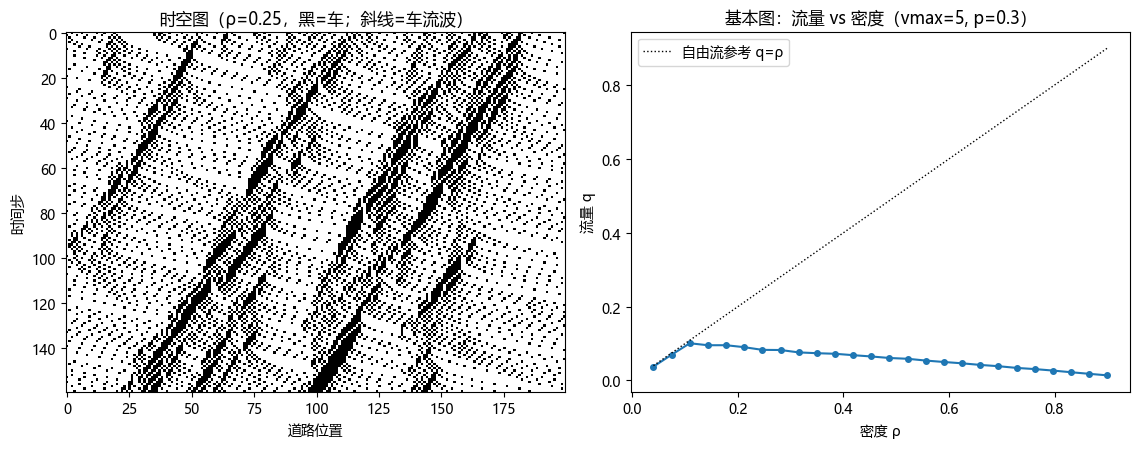

峰值流量 0.101 出现在密度 0.11 附近


In [2]:
def nasch(L, density, vmax=5, p=0.3, steps=120, rng=None):
    road = -np.ones(L, dtype=int)
    n = int(round(L * density))
    road[rng.choice(L, n, replace=False)] = rng.integers(0, vmax + 1, n)
    states = []
    for _ in range(steps):
        occ = road >= 0
        idx = np.where(occ)[0]
        speed = np.where(occ, np.minimum(road + 1, vmax), -1)
        for i in idx:
            d = 1
            while d <= vmax and road[(i + d) % L] == -1:
                d += 1
            speed[i] = min(speed[i], d - 1)
        mask = speed > 0
        speed[mask & (rng.random(L) < p)] -= 1
        new = -np.ones(L, dtype=int)
        for i in idx:
            new[(i + speed[i]) % L] = speed[i]
        road = new
        states.append(road.copy())
    return states

# 时空图：密度 0.25
st = nasch(200, 0.25, steps=160, rng=rng)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
axes[0].imshow(np.array(st) >= 0, aspect="auto", cmap="binary", interpolation="nearest")
axes[0].set(title="时空图（ρ=0.25，黑=车；斜线=车流波）", xlabel="道路位置", ylabel="时间步")

dens = np.linspace(0.04, 0.9, 26)
flows = []
for d in dens:
    f_rep = []
    for _ in range(3):
        st = nasch(200, d, steps=150, rng=rng)
        moving = np.mean([np.mean(s >= 0) for s in st[50:]])       # 占有率
        avg_speed = np.mean([np.mean(s[s >= 0]) for s in st[50:]])
        f_rep.append(moving * avg_speed / 5.0)                     # 归一化流量
    flows.append(np.mean(f_rep))
flows = np.array(flows)
axes[1].plot(dens, flows, "o-", ms=4)
axes[1].plot(dens, dens, "k:", lw=1, label="自由流参考 q=ρ")
axes[1].set(title="基本图：流量 vs 密度（vmax=5, p=0.3）", xlabel="密度 ρ", ylabel="流量 q")
axes[1].legend()
fig.tight_layout(); save(fig, "out-nasch.png"); plt.show()
print(f"峰值流量 {flows.max():.3f} 出现在密度 {dens[np.argmax(flows)]:.2f} 附近")

## 11.3 渗流：相变的又一员

L×L 格点以概率 p 占据，问是否存在左右横穿的连通簇。正方形格点理论临界 p_c≈0.5927。

P_渗流 = 0.5 对应 p ≈ 0.590（理论 p_c = 0.5927）


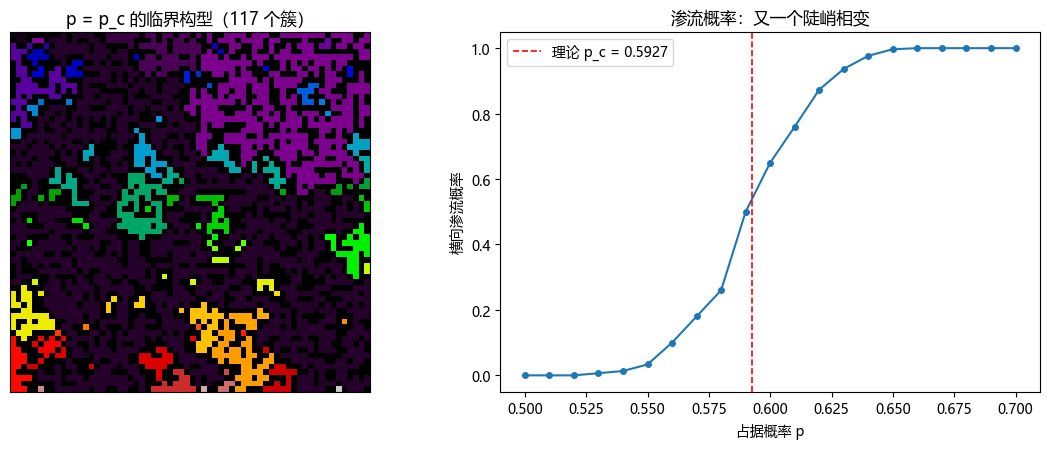

In [3]:
def spans(grid):
    lab, _ = ndimage.label(grid)
    return bool((set(lab[0]) - {0}) & (set(lab[-1]) - {0}))

L, reps = 64, 300
ps = np.linspace(0.50, 0.70, 21)
perc_prob = [np.mean([spans(rng.random((L, L)) < p) for _ in range(reps)]) for p in ps]
p_star = ps[np.argmax(np.array(perc_prob) >= 0.5)]
print(f"P_渗流 = 0.5 对应 p ≈ {p_star:.3f}（理论 p_c = 0.5927）")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
grid = rng.random((L, L)) < 0.5927
lab, ncl = ndimage.label(grid)
axes[0].imshow(lab, cmap="nipy_spectral", interpolation="nearest")
axes[0].set(title=f"p = p_c 的临界构型（{ncl} 个簇）", xticks=[], yticks=[])
axes[1].plot(ps, perc_prob, "o-", ms=4)
axes[1].axvline(0.5927, color="r", ls="--", lw=1.2, label="理论 p_c = 0.5927")
axes[1].set(title="渗流概率：又一个陡峭相变", xlabel="占据概率 p", ylabel="横向渗流概率")
axes[1].legend()
fig.tight_layout(); save(fig, "out-percolation.png"); plt.show()

## 11.4 无标度网络：优先连接造幂律

ER 随机图：度分布泊松；BA 模型（新节点连 m 条边、按度优先）：度分布幂律 P(k)∼k^(−3)。

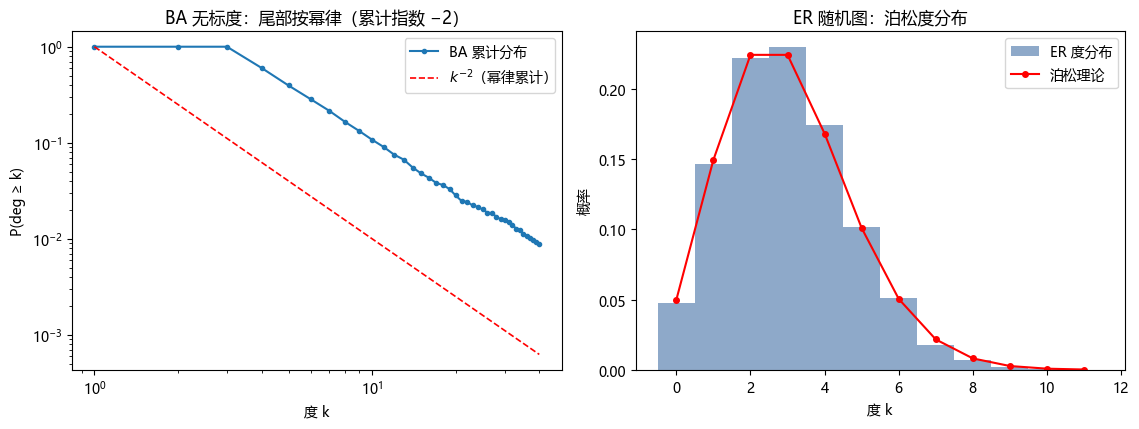

BA: 平均度 6.00，最大度 195；ER: 平均度 3.00，最大度 12


In [4]:
def ba_graph(n, m, rng):
    deg = np.zeros(n, dtype=int)
    targets_hist = np.zeros(n, dtype=int)
    deg[:m+1] = m
    targets_hist[:m+1] = m
    for i in range(m+1, n):
        p = targets_hist[:i] / targets_hist[:i].sum()
        chosen = rng.choice(i, m, replace=False, p=p)
        deg[i] = m
        deg[chosen] += 1
        targets_hist[i] += m
        targets_hist[chosen] += 1
    return deg

def er_graph(n, m, rng):
    deg = np.zeros(n, dtype=int)
    for _ in range(m):
        a, b = rng.integers(0, n, 2)
        while a == b:
            b = rng.integers(0, n)
        deg[a] += 1; deg[b] += 1
    return deg

n, m = 4000, 3
deg_ba = ba_graph(n, m, rng)
deg_er = er_graph(n, int(n*m/2), rng)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
kb = np.arange(1, deg_ba.max()+1)
cdf_ba = np.array([np.mean(deg_ba >= k) for k in kb])
axes[0].loglog(kb[kb <= 40], cdf_ba[kb <= 40], "o-", ms=3, label="BA 累计分布")
axes[0].loglog(kb[kb <= 40], (kb[kb <= 40]/kb[0])**-2.0, "r--", lw=1.2, label=r"$k^{-2}$（幂律累计）")
axes[0].set(title="BA 无标度：尾部按幂律（累计指数 −2）", xlabel="度 k", ylabel="P(deg ≥ k)"); axes[0].legend()
kmax = deg_er.max()
kk = np.arange(0, kmax+1)
axes[1].hist(deg_er, bins=kk-0.5, density=True, color="#8ea9c9", label="ER 度分布")
kk2 = np.arange(0, 12)
axes[1].plot(kk2, stats.poisson.pmf(kk2, m), "ro-", ms=4, label="泊松理论")
axes[1].set(title="ER 随机图：泊松度分布", xlabel="度 k", ylabel="概率"); axes[1].legend()
fig.tight_layout(); save(fig, "out-network.png"); plt.show()
print(f"BA: 平均度 {deg_ba.mean():.2f}，最大度 {deg_ba.max()}；ER: 平均度 {deg_er.mean():.2f}，最大度 {deg_er.max()}")

## 11.5 财富交换：经济学里的玻尔兹曼

5000 人各持 1 元，每次随机二人按随机比例瓜分总财产。稳态：P(w) = e^(−w/T)/T（玻尔兹曼-吉布斯）。

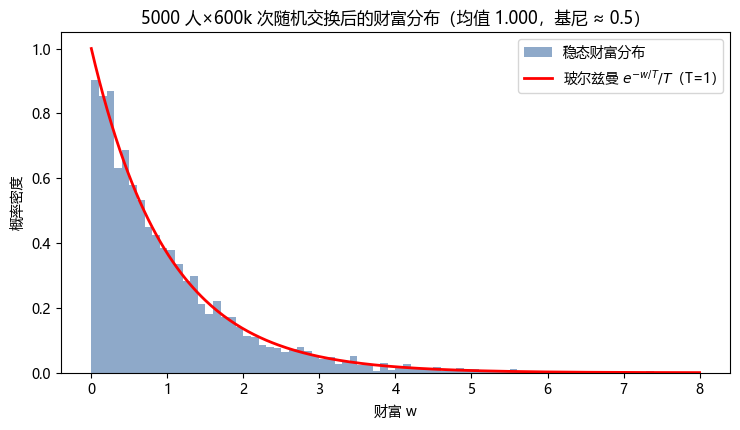

均值 = 1.0000（守恒 = 1），玻尔兹曼均值 = 1 ✓；基尼系数 = 0.500


In [5]:
Np, T_steps = 5000, 600_000
w = np.ones(Np)
for t in range(T_steps):
    i, j = rng.integers(0, Np, 2)
    if i != j:
        f = rng.random()
        tot = w[i] + w[j]
        w[i], w[j] = f*tot, (1-f)*tot

fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.hist(w, bins=80, range=(0, 8), density=True, color="#8ea9c9", label="稳态财富分布")
ww = np.linspace(0, 8, 300)
ax.plot(ww, np.exp(-ww), "r-", lw=2, label=r"玻尔兹曼 $e^{-w/T}/T$（T=1）")
ax.set(title=f"{Np} 人×{T_steps//1000}k 次随机交换后的财富分布（均值 {w.mean():.3f}，基尼 ≈ 0.5）",
       xlabel="财富 w", ylabel="概率密度")
ax.legend(); fig.tight_layout(); save(fig, "out-wealth.png"); plt.show()
sw = np.sort(w)
gini = (2*np.arange(1, Np+1) - Np - 1).dot(sw) / (Np*sw.sum())
print(f"均值 = {w.mean():.4f}（守恒 = 1），玻尔兹曼均值 = 1 ✓；基尼系数 = {gini:.3f}")